# Our conv4 ensemble on the **combined** dataset: H2OPulse `Dataset/` + clean-vein-masks `Processed_Dataset_v3_s7`

**Method (same as the other notebooks):** frozen ImageNet ResNet50 → `conv4_block6_out` → global average pooling (1024 features per frame) → average of three L2 logistic regressions (`C = 0.01`): (1) all frames, (2) one per landmark (dorsal / wrist), (3) original + flipped frames with flip TTA. Trained **frame by frame**.

**Data:** both datasets pooled. Subject IDs are prefixed (`h2o:` / `ext:`) so they can never collide. External dataset: users, hydrated-vs-reference folders and frames chosen exactly as in `h2opulse_model_experiment.ipynb`. Both datasets: up to 5 frames per modality (L/R dorsal, L/R wrist); a visit (= session: one subject, one state) needs ≥ 2 modalities.

**5-fold cross-validation by subject**, stratified by dataset (each fold holds ~1/5 of each dataset's subjects; no subject is ever in train and test). Per fold the ensemble is trained on the training subjects only; the Youden threshold (recall weight 1.25, clipped to [0.05, 0.95]) is chosen on the training subjects' own out-of-fold predictions (inner 4-fold), never on test subjects. Fixed t = 0.5 is also reported.

**Test-time variants:** A. best frame (first file) · B. random frame (10 seeds) · C. all frame combinations · **D. session level = mean of all frames of the visit (primary).** Results are shown for all subjects and **separately per dataset**.

Run from the `H2OPulse/` folder. Outputs go to `H2OPulse/outputs/combined/`.

In [1]:
# Run once if TensorFlow / scikit-learn are missing, then restart the kernel
# %pip install "tensorflow[and-cuda]" scikit-learn matplotlib pandas

In [2]:
# --- Environment check ---
import os, socket
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf

print("Host:", socket.gethostname())
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "NONE - running on CPU (slower, but feature extraction still works)")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError as e:
        print("Could not set memory growth:", e)

I0000 00:00:1795507340.565462 3725788 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795507368.059553 3725788 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Host: gpu10
TensorFlow: 2.22.0-rc1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# --- Configuration ---
PROJECT_DIR = os.getcwd()                                   # the H2OPulse folder
H2O_DATA_ROOT = os.path.join(PROJECT_DIR, "Dataset")
EXT_ROOT = os.path.join(PROJECT_DIR, "external")
OUT_DIR = os.path.join(PROJECT_DIR, "outputs", "combined")
os.makedirs(OUT_DIR, exist_ok=True)


def _find(root, name, want_dir):
    for dirpath, dirnames, filenames in os.walk(root):
        if name in (dirnames if want_dir else filenames):
            return os.path.join(dirpath, name)
    return None


EXT_DATA_ROOT = _find(EXT_ROOT, "Processed_Dataset_v3_s7", want_dir=True)
EXT_CSV = _find(EXT_ROOT, "users_list_final.csv", want_dir=False) or _find(EXT_ROOT, "users_list_v3.csv", want_dir=False)
if not os.path.isdir(H2O_DATA_ROOT):
    raise FileNotFoundError(f"H2OPulse Dataset/ not found: {H2O_DATA_ROOT}")
if EXT_DATA_ROOT is None or EXT_CSV is None:
    raise FileNotFoundError(f"Could not find Processed_Dataset_v3_s7/ and users_list_final.csv under {EXT_ROOT}")

H2O_HANDS = ["left_hand", "right_hand"]
H2O_ROI_SUBDIR = "yolo_vein_roi"
EXT_MODALITIES = ["left_dorsal", "right_dorsal", "left_wrist", "right_wrist"]
EXT_DORSAL = ["left_dorsal", "right_dorsal"]
LANDMARKS = ["dorsal", "wrist"]
DATASETS = ["H2OPulse", "External"]
N_FRAMES = 5
MIN_MODALITIES = 2

IMG_SIZE = (224, 224)
FEATURE_LAYER = "conv4_block6_out"
LOGREG_C = 0.01
BATCH_SIZE = 32

N_SPLITS = 5
INNER_SPLITS = 4
SEED = 801
N_RANDOM_REPEATS = 10
FIXED_THRESHOLDS = [0.5]

FEATURES_CACHE = os.path.join(OUT_DIR, f"features_{FEATURE_LAYER}_{IMG_SIZE[0]}.npz")
FEATURES_FLIP_CACHE = os.path.join(OUT_DIR, f"features_{FEATURE_LAYER}_{IMG_SIZE[0]}_hflip.npz")
FINAL_MODEL_PATH = os.path.join(OUT_DIR, "conv4_ensemble_combined.keras")
FINAL_CONFIG_PATH = os.path.join(OUT_DIR, "conv4_ensemble_combined_config.json")

print("H2OPulse data :", H2O_DATA_ROOT)
print("External data :", EXT_DATA_ROOT)
print("External CSV  :", EXT_CSV)
print("OUT_DIR       :", OUT_DIR)

H2OPulse data : /bigdata/decristofarolab/mbhui008/olid/H2OPulse/Dataset
External data : /bigdata/decristofarolab/mbhui008/olid/H2OPulse/external/clean_vein_masks/Processed_Dataset_v3_s7
External CSV  : /bigdata/decristofarolab/mbhui008/olid/H2OPulse/external/user_selection/users_list_final.csv
OUT_DIR       : /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/combined


In [4]:
import glob, json
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, auc, balanced_accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score, roc_curve,
)

tf.keras.utils.set_random_seed(SEED)

## 1. Collect frames from both datasets

In [5]:
def _imgs(folder, exts=(".jpg", ".jpeg", ".png")):
    if not os.path.isdir(folder):
        return []
    return sorted(os.path.join(folder, n) for n in os.listdir(folder)
                  if not n.startswith(".") and n.lower().endswith(exts))


rows, empty = [], []

# ---- H2OPulse Dataset/: <subject>/<hydrated|dehydrated>/<hand>/<landmark>/yolo_vein_roi/
h2o_subjects = sorted(d for d in os.listdir(H2O_DATA_ROOT)
                      if os.path.isdir(os.path.join(H2O_DATA_ROOT, d)) and not d.startswith("."))
for uid in h2o_subjects:
    for label, state in [(1, "dehydrated"), (0, "hydrated")]:
        for hand in H2O_HANDS:
            for lm in LANDMARKS:
                mod = f"{hand.split('_')[0]}_{lm}"
                paths = _imgs(os.path.join(H2O_DATA_ROOT, uid, state, hand, lm, H2O_ROI_SUBDIR))[:N_FRAMES]
                if not paths:
                    empty.append(("H2OPulse", uid, state, mod))
                for fi, p in enumerate(paths):
                    rows.append({"dataset": "H2OPulse", "user_id": f"h2o:{uid}", "label": label, "modality": mod,
                                 "landmark": lm, "frame_idx": fi, "path": p})

# ---- External: same user selection + hydrated/reference rule as their notebook
_raw = pd.read_csv(EXT_CSV)
_u = _raw.iloc[:, :5].copy()
_u.columns = ["user_id", "ok_d", "hyd_ref_d", "ok_w", "hyd_ref_w"]
_ok = {(1, 1), (1, 0), (0, 1), (1, -1), (-1, 1)}
_u = _u[[(d, w) in _ok for d, w in zip(_u.ok_d, _u.ok_w)]].reset_index(drop=True)
ext_meta = _u.set_index("user_id").to_dict("index")
ext_users = sorted(set(_u.user_id))
for uid in ext_users:
    meta = ext_meta[uid]
    for label, state in [(1, "dehydrated"), (0, "hydrated")]:
        for mod in EXT_MODALITIES:
            use_h = int(meta["hyd_ref_d" if mod in EXT_DORSAL else "hyd_ref_w"])
            sub = "dehydrated" if state == "dehydrated" else ("hydrated" if use_h else "reference")
            paths = _imgs(os.path.join(EXT_DATA_ROOT, uid, sub, mod), exts=(".png",))[:N_FRAMES]
            if not paths:
                empty.append(("External", uid, state, mod))
            for fi, p in enumerate(paths):
                rows.append({"dataset": "External", "user_id": f"ext:{uid}", "label": label, "modality": mod,
                             "landmark": "dorsal" if mod in EXT_DORSAL else "wrist", "frame_idx": fi, "path": p})

frames = pd.DataFrame(rows)
if empty:
    print(f"[WARN] {len(empty)} empty/missing modality folders (e.g. {empty[0]})")

y_all = frames.label.values.astype(int)
user_arr = frames.user_id.values
lm_arr = frames.landmark.values
ds_arr = frames.dataset.values
ds_code = (ds_arr == "External").astype(int)

print(frames.groupby("dataset").agg(subjects=("user_id", "nunique"), frames=("path", "size"),
                                    dehydrated=("label", "sum")).assign(
      visits=frames.groupby("dataset").apply(lambda d: d.groupby(["user_id", "label"]).ngroups)).to_string())
print(f"\nTotal: {frames.user_id.nunique()} subjects, {len(frames)} frames, "
      f"{frames.groupby(['user_id', 'label']).ngroups} visits")

          subjects  frames  dehydrated  visits
dataset                                       
External        74    2960        1480     148
H2OPulse        86    3291        1646     172

Total: 160 subjects, 6251 frames, 320 visits


## 2. Features: frozen ResNet50 → conv4 → global average pooling (original + flipped, cached)

In [6]:
_base = ResNet50(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
_base.trainable = False
feature_extractor = keras.Model(
    _base.input,
    layers.GlobalAveragePooling2D(name="gap")(_base.get_layer(FEATURE_LAYER).output),
    name=f"resnet50_{FEATURE_LAYER}_gap",
)


def load_image(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.cast(tf.image.resize(img, IMG_SIZE), tf.float32)
    return preprocess_input(img)


def image_dataset(paths, flip=False):
    fn = (lambda p: tf.image.flip_left_right(load_image(p))) if flip else load_image
    return (tf.data.Dataset.from_tensor_slices(np.asarray(paths, dtype=object))
            .map(fn, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))


def cached_features(cache_path, paths, flip):
    if os.path.exists(cache_path):
        c = np.load(cache_path, allow_pickle=True)
        if list(c["paths"]) == list(paths):
            print("Loaded cached features:", cache_path)
            return c["X"]
    X = feature_extractor.predict(image_dataset(paths, flip=flip), verbose=1)
    np.savez_compressed(cache_path, X=X, paths=np.asarray(paths, dtype=object))
    print("Saved features:", cache_path)
    return X


X_all = cached_features(FEATURES_CACHE, frames.path.values, flip=False)
X_flip = cached_features(FEATURES_FLIP_CACHE, frames.path.values, flip=True)
print("Feature matrices:", X_all.shape, X_flip.shape)

196/196 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step
Saved features: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/combined/features_conv4_block6_out_224.npz
196/196 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step
Saved features: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/combined/features_conv4_block6_out_224_hflip.npz
Feature matrices: (6251, 1024) (6251, 1024)


## 3. Ensemble, threshold and visit helpers

In [7]:
def make_classifier():
    return make_pipeline(StandardScaler(), LogisticRegression(C=LOGREG_C, max_iter=3000))


def fit_ensemble(idx):
    idx = np.asarray(idx)
    ens = {"all": make_classifier().fit(X_all[idx], y_all[idx]), "landmark": {}}
    for lm in LANDMARKS:
        j = idx[lm_arr[idx] == lm]
        ens["landmark"][lm] = make_classifier().fit(X_all[j], y_all[j])
    ens["flip"] = make_classifier().fit(np.vstack([X_all[idx], X_flip[idx]]), np.r_[y_all[idx], y_all[idx]])
    return ens


def predict_ensemble(ens, idx):
    idx = np.asarray(idx)
    X, Xf, lms = X_all[idx], X_flip[idx], lm_arr[idx]
    p_all = ens["all"].predict_proba(X)[:, 1]
    p_lm = np.zeros(len(idx))
    for lm, m in ens["landmark"].items():
        k = lms == lm
        if k.any():
            p_lm[k] = m.predict_proba(X[k])[:, 1]
    p_flip = 0.5 * (ens["flip"].predict_proba(X)[:, 1] + ens["flip"].predict_proba(Xf)[:, 1])
    return (p_all + p_lm + p_flip) / 3


def youden_threshold(y_true, y_prob, recall_weight=1.25):
    if len(set(y_true)) < 2:
        return 0.5
    fpr, tpr, thresh = roc_curve(y_true, y_prob)
    idx = int(np.argmax(recall_weight * tpr - fpr))
    return float(np.clip(float(thresh[idx]), 0.05, 0.95))


METRICS = ["Accuracy", "Precision", "F1", "Recall (Sensitivity)", "Specificity", "Balanced Accuracy", "AUROC"]


def metrics(y, p, t):
    y, p = np.asarray(y), np.asarray(p)
    pred = (p >= t).astype(int)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Recall (Sensitivity)": recall_score(y, pred, zero_division=0),
        "Specificity": recall_score(y, pred, pos_label=0, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y, pred),
        "AUROC": roc_auc_score(y, p) if len(set(y)) > 1 else 0.5,
    }


def scen_from(prob, idx):
    sub = frames.iloc[idx].assign(p=prob[idx]).sort_values("frame_idx")
    return {(u, int(l), m): g.p.values for (u, l, m), g in sub.groupby(["user_id", "label", "modality"])}


def build_samples(scen, mode, choice=None):
    per_visit = defaultdict(list)
    for k in sorted(scen):
        per_visit[(k[0], k[1])].append(k)
    out = {}
    for v, keys in per_visit.items():
        if len(keys) < MIN_MODALITIES:
            continue
        arrs = [scen[k] for k in keys]
        if mode == "frame":
            out[v] = np.array([np.mean([scen[k][choice[k]] for k in keys])])
        elif mode == "combos":
            out[v] = np.mean(np.stack(np.meshgrid(*arrs, indexing="ij")), axis=0).ravel()
        elif mode == "session":
            out[v] = np.array([np.concatenate(arrs).mean()])
    return out


def stack_samples(s):
    keys = sorted(s)
    if not keys:
        return np.array([]), np.array([])
    return (np.concatenate([np.full(len(s[k]), k[1]) for k in keys]),
            np.concatenate([s[k] for k in keys]))


def dataset_of(user_id):
    return "H2OPulse" if user_id.startswith("h2o:") else "External"


all_scen_keys = sorted({(u, int(l), m) for u, l, m in frames[["user_id", "label", "modality"]].itertuples(index=False)})
n_frames_of = frames.groupby(["user_id", "label", "modality"]).size().to_dict()

## 4. 5-fold cross-validation by subject (stratified by dataset)

In [8]:
outer = list(StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_all, ds_code, groups=user_arr))
oof_test = np.full(len(y_all), np.nan)
train_scens, test_scens = [], []

for f, (tr_idx, te_idx) in enumerate(outer, 1):
    assert not set(user_arr[tr_idx]) & set(user_arr[te_idx]), "subject leakage"
    ens = fit_ensemble(tr_idx)
    oof_test[te_idx] = predict_ensemble(ens, te_idx)

    inner_p = np.full(len(y_all), np.nan)
    inner = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED)
    for itr, ite in inner.split(tr_idx, ds_code[tr_idx], groups=user_arr[tr_idx]):
        inner_p[tr_idx[ite]] = predict_ensemble(fit_ensemble(tr_idx[itr]), tr_idx[ite])

    train_scens.append(scen_from(inner_p, tr_idx))
    test_scens.append(scen_from(oof_test, te_idx))
    n_te = pd.Series(ds_arr[te_idx]).groupby(pd.Series(ds_arr[te_idx])).size()
    te_subj = pd.Series(user_arr[te_idx]).map(dataset_of).groupby(pd.Series(user_arr[te_idx])).first().value_counts()
    print(f"fold {f}: test subjects H2OPulse={te_subj.get('H2OPulse', 0)} External={te_subj.get('External', 0)} | "
          f"test frame AUROC={roc_auc_score(y_all[te_idx], oof_test[te_idx]):.3f}")

print(f"\nPooled frame-level AUROC (out-of-fold): all={roc_auc_score(y_all, oof_test):.3f}  " +
      "  ".join(f"{d}={roc_auc_score(y_all[ds_arr == d], oof_test[ds_arr == d]):.3f}" for d in DATASETS))
frames.assign(oof_prob=oof_test).to_csv(os.path.join(OUT_DIR, "frame_oof_probs.csv"), index=False)


def eval_experiment(mode, choice=None):
    # Returns fold table, pooled metrics (all + per dataset) and mean fold threshold
    rows_, fold_t, oy, op, ok = [], [], [], [], []
    for f in range(N_SPLITS):
        tr_y, tr_p = stack_samples(build_samples(train_scens[f], mode, choice))
        te_s = build_samples(test_scens[f], mode, choice)
        te_y, te_p = stack_samples(te_s)
        te_ds = np.concatenate([np.full(len(te_s[k]), dataset_of(k[0])) for k in sorted(te_s)])
        t = youden_threshold(tr_y, tr_p)
        fold_t.append(t); oy.append(te_y); op.append(te_p); ok.append(te_ds)
        base = {"fold": f + 1, "n_test_visits": len(te_s), "n_test_samples": len(te_y)}
        rows_.append({**base, "threshold": "youden_train", "t": t, **metrics(te_y, te_p, t)})
        for tf_ in FIXED_THRESHOLDS:
            rows_.append({**base, "threshold": f"fixed_{tf_}", "t": tf_, **metrics(te_y, te_p, tf_)})
    oy, op, ok = np.concatenate(oy), np.concatenate(op), np.concatenate(ok)
    t_mean = float(np.mean(fold_t))
    pooled = {}
    for thr, t in [("youden_train", t_mean)] + [(f"fixed_{x}", x) for x in FIXED_THRESHOLDS]:
        pooled[thr] = {"All": metrics(oy, op, t), **{d: metrics(oy[ok == d], op[ok == d], t) for d in DATASETS}}
    return pd.DataFrame(rows_), pooled, t_mean


summary_rows, fold_tables = [], []


def add_summary(name, fdf, pooled, t_mean):
    for thr in fdf.threshold.unique():
        sub = fdf[fdf.threshold == thr]
        row = {"Experiment": name, "threshold": thr,
               "t (mean fold)": t_mean if thr == "youden_train" else float(thr.split("_", 1)[1])}
        for m in METRICS:
            row[f"{m} (fold mean)"] = sub[m].mean()
            row[f"{m} (fold std)"] = sub[m].std()
            for scope in ["All"] + DATASETS:
                row[f"{m} (pooled {scope})"] = pooled[thr][scope][m]
        summary_rows.append(row)


def _avg_pooled(pooled_list):
    return {thr: {scope: {m: float(np.mean([p[thr][scope][m] for p in pooled_list])) for m in METRICS}
                  for scope in ["All"] + DATASETS} for thr in pooled_list[0]}


fdf, pooled, t_ = eval_experiment("frame", {k: 0 for k in all_scen_keys})
fdf.insert(0, "experiment", "A. Best frame"); fold_tables.append(fdf)
add_summary("A. Best frame (first file)", fdf, pooled, t_)

_rf, _rp, _rt = [], [], []
for r in range(N_RANDOM_REPEATS):
    rng = np.random.default_rng(SEED + r)
    rand_idx = {k: int(rng.integers(n_frames_of[k])) for k in all_scen_keys}
    fdf_r, pooled_r, t_r = eval_experiment("frame", rand_idx)
    fdf_r.insert(0, "experiment", "B. Random frame"); fdf_r.insert(1, "repeat", r)
    _rf.append(fdf_r); _rp.append(pooled_r); _rt.append(t_r)
fdf_rand = pd.concat(_rf, ignore_index=True); fold_tables.append(fdf_rand)
add_summary(f"B. Random frame ({N_RANDOM_REPEATS} seeds)", fdf_rand, _avg_pooled(_rp), float(np.mean(_rt)))

fdf, pooled, t_ = eval_experiment("combos")
fdf.insert(0, "experiment", "C. All frame combinations"); fold_tables.append(fdf)
add_summary("C. All frame combinations", fdf, pooled, t_)

fdf_D, pooled_D, t_D = eval_experiment("session")
fdf_D.insert(0, "experiment", "D. Session level"); fold_tables.append(fdf_D)
add_summary("D. Session level (mean of all frames)", fdf_D, pooled_D, t_D)

summary = pd.DataFrame(summary_rows)
pd.concat(fold_tables, ignore_index=True).to_csv(os.path.join(OUT_DIR, "cv_folds.csv"), index=False)
summary.to_csv(os.path.join(OUT_DIR, "cv_summary.csv"), index=False)
print("Saved cv_folds.csv / cv_summary.csv to", OUT_DIR)

fold 1: test subjects H2OPulse=17 External=15 | test frame AUROC=0.587
fold 2: test subjects H2OPulse=18 External=15 | test frame AUROC=0.599
fold 3: test subjects H2OPulse=17 External=15 | test frame AUROC=0.622
fold 4: test subjects H2OPulse=17 External=14 | test frame AUROC=0.642
fold 5: test subjects H2OPulse=17 External=15 | test frame AUROC=0.606

Pooled frame-level AUROC (out-of-fold): all=0.610  H2OPulse=0.604  External=0.617
Saved cv_folds.csv / cv_summary.csv to /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/combined


## 5. Results


Combined dataset — fold mean — threshold: Youden on training subjects (inner OOF)
Experiment                                      Acc     Prec       F1      Rec     Spec   BalAcc    AUROC
--------------------------------------------------------------------------------------------------------
A. Best frame (first file)                    0.666    0.663    0.674    0.695    0.637    0.666    0.690
B. Random frame (10 seeds)                    0.622    0.611    0.655    0.726    0.518    0.622    0.687
C. All frame combinations                     0.623    0.610    0.659    0.726    0.517    0.622    0.686
D. Session level (mean of all frames)         0.608    0.617    0.658    0.749    0.466    0.608    0.704

Combined dataset — pooled All — threshold: Youden on training subjects (inner OOF)
Experiment                                      Acc     Prec       F1      Rec     Spec   BalAcc    AUROC
--------------------------------------------------------------------------------------------

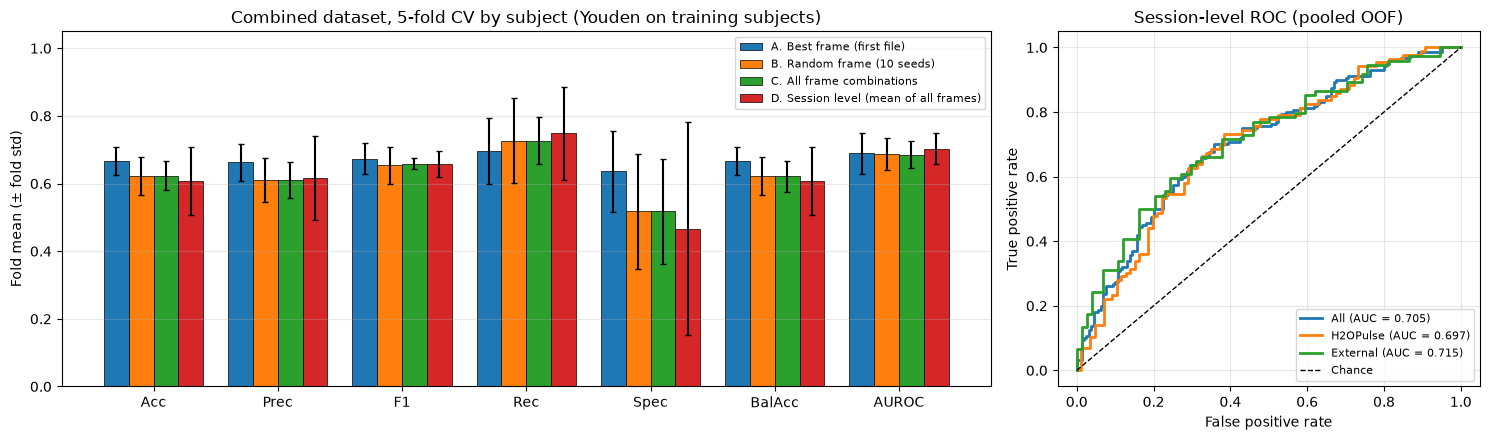

In [9]:
_short = {"Accuracy": "Acc", "Precision": "Prec", "F1": "F1", "Recall (Sensitivity)": "Rec",
          "Specificity": "Spec", "Balanced Accuracy": "BalAcc", "AUROC": "AUROC"}
_tags = {"youden_train": "Youden on training subjects (inner OOF)", "fixed_0.5": "fixed t=0.5"}

for thr in ["youden_train"] + [f"fixed_{t}" for t in FIXED_THRESHOLDS]:
    for kind in ["fold mean", "pooled All", "pooled H2OPulse", "pooled External"]:
        print("\n" + "=" * 104)
        print(f"Combined dataset — {kind} — threshold: {_tags.get(thr, thr)}")
        print("=" * 104)
        print(f"{'Experiment':<42}" + "".join(f"{_short[m]:>9}" for m in METRICS))
        print("-" * 104)
        for _, row in summary[summary.threshold == thr].iterrows():
            print(f"{row['Experiment']:<42}" + "".join(f"{row[f'{m} ({kind})']:>9.3f}" for m in METRICS))

# ---- headline: session level (D) ----
_D = fdf_D[fdf_D.threshold == "youden_train"]
_cols = [("Accuracy", "accuracy"), ("Precision", "precision"), ("Recall (Sensitivity)", "recall"),
         ("F1", "F1"), ("AUROC", "AUC")]
print("\n" + "#" * 80)
print("SESSION LEVEL (D), combined dataset — Youden threshold on training subjects")
print("#" * 80)
print(_D[["fold", "n_test_visits", "t", "Accuracy", "Precision", "Recall (Sensitivity)", "F1", "AUROC"]]
      .rename(columns={"Recall (Sensitivity)": "Recall"}).round(3).to_string(index=False))
print("\nMean ± SD across folds:")
for m, lab in _cols:
    print(f"  {lab:10s} {_D[m].mean():.3f} ± {_D[m].std():.3f}")
for thr, lab_t in [("youden_train", f"Youden, t = mean fold threshold {t_D:.3f}"), ("fixed_0.5", "t = 0.5")]:
    print(f"\nPooled session-level results ({lab_t}):")
    print(f"  {'':10s}" + "".join(f"{s:>12}" for s in ["All"] + DATASETS))
    for m, lab in _cols:
        print(f"  {lab:10s}" + "".join(f"{pooled_D[thr][s][m]:>12.3f}" for s in ["All"] + DATASETS))

print("\nFor reference (each dataset trained alone):")
print("  H2OPulse in-domain ensemble (resnet50_conv4_ensemble_reffree.ipynb): session acc 0.698, session AUC 0.753 (t = 0.5)")
print("  External: their morphology LR 0.7365 acc / 0.782 AUROC; our in-domain run -> see conv4_ensemble_train_external.ipynb")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
_y = summary[summary.threshold == "youden_train"].set_index("Experiment")
ax = axes[0]
w = 0.8 / len(_y)
xs = np.arange(len(METRICS))
for i, (name, row) in enumerate(_y.iterrows()):
    ax.bar(xs + (i - (len(_y) - 1) / 2) * w, [row[f"{m} (fold mean)"] for m in METRICS], w,
           yerr=[row[f"{m} (fold std)"] for m in METRICS], capsize=2, label=name, edgecolor="black", linewidth=0.5)
ax.set_xticks(xs); ax.set_xticklabels([_short[m] for m in METRICS])
ax.set_ylim(0, 1.05); ax.set_ylabel("Fold mean (± fold std)")
ax.set_title("Combined dataset, 5-fold CV by subject (Youden on training subjects)")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)

ax = axes[1]
_vy, _vp, _vd = [], [], []
for f in range(N_SPLITS):
    for k, v in build_samples(test_scens[f], "session").items():
        _vy.append(k[1]); _vp.append(v[0]); _vd.append(dataset_of(k[0]))
_vy, _vp, _vd = map(np.array, (_vy, _vp, _vd))
for scope, mask in [("All", np.ones(len(_vy), bool))] + [(d, _vd == d) for d in DATASETS]:
    fpr, tpr, _ = roc_curve(_vy[mask], _vp[mask])
    ax.plot(fpr, tpr, lw=2, label=f"{scope} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Session-level ROC (pooled OOF)"); ax.legend(loc="lower right", fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "cv_results.png"), dpi=150)
plt.show()

## 6. Train the final ensemble on all subjects of both datasets and save one `.keras` file

In [10]:
final_ens = fit_ensemble(np.arange(len(y_all)))
DEPLOY_THRESHOLD = t_D
print(f"Trained on {len(y_all)} frames from {frames.user_id.nunique()} subjects | "
      f"session-level deployment threshold = {DEPLOY_THRESHOLD:.3f}")


def to_dense(pipelines):
    W, B = [], []
    for pipe in pipelines:
        sc, lr = pipe.named_steps["standardscaler"], pipe.named_steps["logisticregression"]
        w = lr.coef_.ravel() / sc.scale_
        W.append(w)
        B.append(lr.intercept_[0] - np.sum(w * sc.mean_))
    return [np.stack(W, axis=1).astype("float32"), np.array(B, dtype="float32")]


img_in = keras.Input(shape=(*IMG_SIZE, 3), name="image")
lm_in = keras.Input(shape=(len(LANDMARKS),), name="landmark")
feat = feature_extractor(img_in)
_W = IMG_SIZE[1]
hflip_matrix = layers.Dense(_W, use_bias=False, trainable=False, name="hflip_matrix")
img_flip = layers.Permute((1, 3, 2), name="hflip_back")(hflip_matrix(layers.Permute((1, 3, 2), name="hflip_to_w")(img_in)))
feat_flip = feature_extractor(img_flip)

head_all = layers.Dense(1, activation="sigmoid", name="head_all")
head_lm = layers.Dense(len(LANDMARKS), activation="sigmoid", name="head_per_landmark")
head_flip = layers.Dense(1, activation="sigmoid", name="head_flip")
p_all = head_all(feat)
p_lm = layers.Dot(axes=1, name="pick_landmark")([head_lm(feat), lm_in])
p_flip = layers.Average(name="flip_tta")([head_flip(feat), head_flip(feat_flip)])
out = layers.Average(name="ensemble")([p_all, p_lm, p_flip])
final_model = keras.Model({"image": img_in, "landmark": lm_in}, out, name="resnet50_conv4_ensemble_combined")

hflip_matrix.set_weights([np.eye(_W, dtype="float32")[::-1]])
head_all.set_weights(to_dense([final_ens["all"]]))
head_lm.set_weights(to_dense([final_ens["landmark"][lm] for lm in LANDMARKS]))
head_flip.set_weights(to_dense([final_ens["flip"]]))


def model_dataset(paths, landmarks):
    onehot = np.eye(len(LANDMARKS), dtype="float32")[[LANDMARKS.index(l) for l in landmarks]]
    ds = tf.data.Dataset.from_tensor_slices((np.asarray(paths, dtype=object), onehot))
    return (ds.map(lambda p, l: {"image": load_image(p), "landmark": l}, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))


chk = np.random.default_rng(0).choice(len(frames), size=min(200, len(frames)), replace=False)
p_keras = final_model.predict(model_dataset(frames.path.values[chk], lm_arr[chk]), verbose=0).ravel()
p_sklearn = predict_ensemble(final_ens, chk)
print(f"Max |keras - sklearn| = {np.max(np.abs(p_keras - p_sklearn)):.2e}  (should be ~1e-5 or smaller)")

final_model.save(FINAL_MODEL_PATH)
_reloaded = keras.models.load_model(FINAL_MODEL_PATH)
_d = np.max(np.abs(_reloaded.predict(model_dataset(frames.path.values[chk], lm_arr[chk]), verbose=0).ravel() - p_keras))
json.dump({"session_threshold": DEPLOY_THRESHOLD, "landmarks": LANDMARKS, "img_size": list(IMG_SIZE),
           "feature_layer": FEATURE_LAYER, "logreg_C": LOGREG_C, "datasets": DATASETS,
           "session_rule": "mean P(dehydrated) over all frames of a visit (>= 2 modalities)"},
          open(FINAL_CONFIG_PATH, "w"), indent=2)
print("Saved:", FINAL_MODEL_PATH, f"(reload check: max diff {_d:.1e})")
print("Saved:", FINAL_CONFIG_PATH)

Trained on 6251 frames from 160 subjects | session-level deployment threshold = 0.450
Max |keras - sklearn| = 1.08e-03  (should be ~1e-5 or smaller)
Saved: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/combined/conv4_ensemble_combined.keras (reload check: max diff 0.0e+00)
Saved: /bigdata/decristofarolab/mbhui008/olid/H2OPulse/outputs/combined/conv4_ensemble_combined_config.json
